# 00 · Intraday bars, features and summaries

`nanoprobe-array` turns the stored one-minute bars into what intraday research needs: a
regular-session clock, bars of any size with an explicit rule for empty bars, official auction
prices, per-bar features, and a table of daily intraday summaries for every security since
2003. Design: `docs/decisions/0014-intraday.md`.

1. the session clock (early closes)
2. bars on a grid: empty bars and halts
3. the closing auction is not in the minute bars
4. features through a day
5. the whole market, one day at a time
6. daily summaries: overnight vs intraday, and intraday momentum on SPY

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from nanoprobe_array import FEATURES, Nanoprobe
from subspace_probe import style, timed

style()
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
p = Nanoprobe()
NY = "America/New_York"
def hhmm(c):
    return pl.col(c).dt.convert_time_zone(NY).dt.strftime("%H:%M")


p.status()

{'root': '/Users/yuriturygin/market_data/nanoprobe_array',
 'built_at': '2026-11-05T00:29:53+00:00',
 'years': 24,
 'rows': 49475335,
 'first_date': '2003-09-10',
 'last_date': '2026-11-03',
 'minute_bars_last': '2026-11-03',
 'behind': False}

## 1 · The session clock

Bars are anchored at the open and labelled by their **end**: a bar covers `[bar_start, bar_end)`
and every value at it uses only minutes that start before `bar_end`. The last bar ends at the
close, so with 1-hour bars the last one is 30 minutes long, and the day after Thanksgiving
(closing at 13:00) has fewer bars.

In [2]:
for day in ["2025-11-26", "2025-11-28"]:
    c = p.clock(day, freq="1h")
    print(day, f"{c.height} bars")
    print(c.select("bar", hhmm("bar_start").alias("start"), hhmm("bar_end").alias("end"),
                   "minutes_from_open", "minutes_to_close", "last"))

2025-11-26 7 bars
shape: (7, 6)
┌─────┬───────┬───────┬───────────────────┬──────────────────┬───────┐
│ bar ┆ start ┆ end   ┆ minutes_from_open ┆ minutes_to_close ┆ last  │
│ --- ┆ ---   ┆ ---   ┆ ---               ┆ ---              ┆ ---   │
│ i32 ┆ str   ┆ str   ┆ i32               ┆ i32              ┆ bool  │
╞═════╪═══════╪═══════╪═══════════════════╪══════════════════╪═══════╡
│ 0   ┆ 09:30 ┆ 10:30 ┆ 60                ┆ 330              ┆ false │
│ 1   ┆ 10:30 ┆ 11:30 ┆ 120               ┆ 270              ┆ false │
│ 2   ┆ 11:30 ┆ 12:30 ┆ 180               ┆ 210              ┆ false │
│ 3   ┆ 12:30 ┆ 13:30 ┆ 240               ┆ 150              ┆ false │
│ 4   ┆ 13:30 ┆ 14:30 ┆ 300               ┆ 90               ┆ false │
│ 5   ┆ 14:30 ┆ 15:30 ┆ 360               ┆ 30               ┆ false │
│ 6   ┆ 15:30 ┆ 16:00 ┆ 390               ┆ 0                ┆ true  │
└─────┴───────┴───────┴───────────────────┴──────────────────┴───────┘
2025-11-28 4 bars
shape: (4, 6)
┌─────┬──────

## 2 · Bars on a grid: empty bars and halts

`resample` returns only bars with prints. `fill="grid"` adds every empty bar: volume 0,
`stale` true and the previous close as its prices, carried within the day only. Small caps
have many empty bars; a halt is a run of them. On 9 March 2020 the S&P 500 fell 7% at the
open and trading stopped market-wide from 09:34 to 09:49.

ASTE on 2026-10-30: 33 of 78 five-minute bars empty


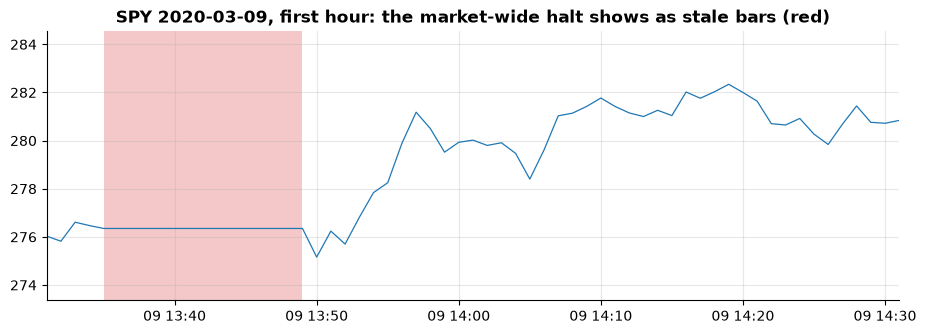

In [3]:
small = p.bars("ASTE", "2026-10-30", freq="5min", fill="grid")
print(f"ASTE on 2026-10-30: {small['stale'].sum()} of {small.height} five-minute bars empty")

halt = p.bars("SPY", "2020-03-09", freq="1min", fill="grid")
fig, ax = plt.subplots(figsize=(11, 3.5))
t = halt["bar_end"].dt.convert_time_zone(NY)
ax.plot(t, halt["close"], lw=0.9)
for ts in halt.filter("stale")["bar_end"].dt.convert_time_zone(NY):
    ax.axvspan(ts - np.timedelta64(1, "m"), ts, color="tab:red", alpha=0.25, lw=0)
ax.set_xlim(t[0], t[60])
ax.set_title("SPY 2020-03-09, first hour: the market-wide halt shows as stale bars (red)")
plt.show()

## 3 · The closing auction is not in the minute bars

The last minute's close is not the official close: the closing auction prints after it and is
a large part of the day's volume. `auctions()` gives the official prices (and the previous close
on today's share basis, splits and dividends taken out). An intraday backtest must price
market-on-close fills at `close_auction`, never at the last bar.

In [4]:
names = ["SPY", "AAPL", "ASTE", "CRMT"]
last = (p.bars(names, "2026-10-01", "2026-10-30", freq="5min")
          .sort("bar_end").group_by("date", "security_id").agg(pl.col("ticker").last(), pl.col("close").last().alias("last_bar")))
auc = p.auctions(names, "2026-10-01", "2026-10-30")
gap = auc.join(last, on=["date", "security_id"]).with_columns(bp=((pl.col("close_auction") / pl.col("last_bar") - 1).abs() * 1e4))
gap.group_by("ticker").agg(pl.col("bp").mean().round(1).alias("mean |close vs last bar| bp")).sort("ticker")

ticker,mean |close vs last bar| bp
str,f64
"""AAPL""",2.1
"""ASTE""",9.0
"""CRMT""",122.1
"""SPY""",0.5


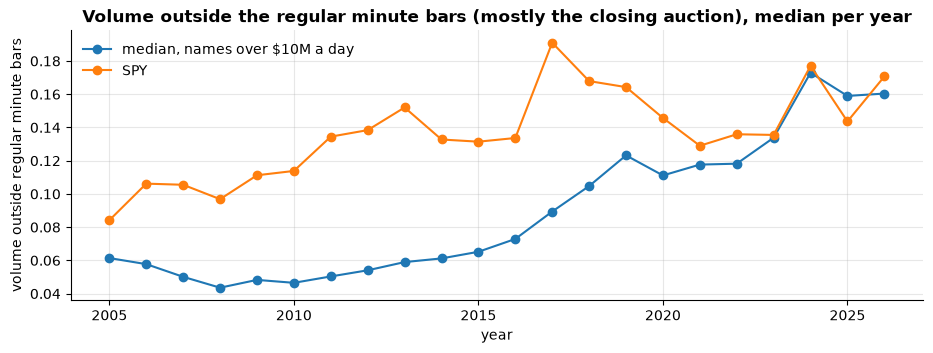

In [5]:
s = p.summaries(start="2005-01-01", columns=["date", "ticker", "auction_share", "volume", "close"])
liquid = s.filter(pl.col("close") * pl.col("volume") > 1e7)
by_year = (liquid.group_by(pl.col("date").dt.year().alias("year"))
           .agg(pl.col("auction_share").median().alias("median, names over $10M a day"))
           .join(s.filter(pl.col("ticker") == "SPY").group_by(pl.col("date").dt.year().alias("year"))
                  .agg(pl.col("auction_share").median().alias("SPY")), on="year").sort("year"))
ax = by_year.to_pandas().set_index("year").plot(figsize=(11, 3.5), marker="o")
ax.set_ylabel("volume outside regular minute bars")
ax.set_title("Volume outside the regular minute bars (mostly the closing auction), median per year")
plt.show()

## 4 · Features through a day

Every feature is computed per security and day from bars up to each bar's end; `vol_ratio`
(volume so far against its usual level at that time of day) uses only earlier days. A test
in the package perturbs everything after a bar and checks that nothing before it changes.

In [6]:
pl.DataFrame([{"name": f.name, "needs": f.needs, "meaning": f.description} for f in FEATURES.values()])

name,needs,meaning
str,str,str
"""ret_bar""","""""","""close / previous bar's close -…"
"""ret_open""","""""","""close / the day's first open -…"
"""ret_prev""","""prev_close""","""close / previous day's officia…"
"""gap""","""prev_close""","""the day's first open / previou…"
"""vwap_dev""","""""","""close / VWAP since the open - …"
"""rvol""","""""","""realized volatility since the …"
"""range_pos""","""""","""(close - low so far) / (high s…"
"""or_high""","""""","""high of the opening range (bar…"
"""or_low""","""""","""low of the opening range; null…"


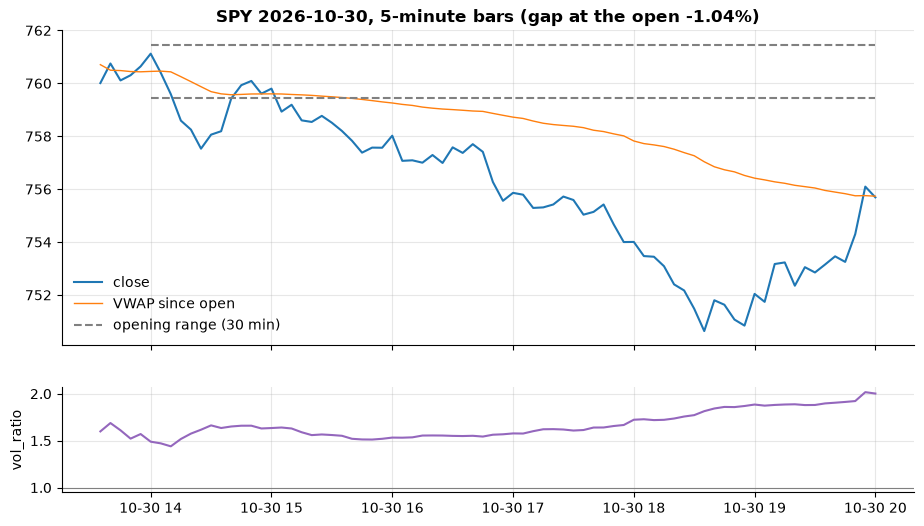

In [7]:
day = "2026-10-30"
f = p.bars("SPY", "2026-09-25", day, freq="5min", fill="grid", prev_close=True,
           features=["vwap_dev", "or_high", "or_low", "or_break", "vol_ratio", "gap"]).filter(pl.col("date").cast(pl.String) == day)
t = f["bar_end"].dt.convert_time_zone(NY)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(t, f["close"], label="close")
ax.plot(t, f["close"] / (1 + f["vwap_dev"]), label="VWAP since open", lw=1)
ax.plot(t, f["or_high"], "--", color="gray", label="opening range (30 min)")
ax.plot(t, f["or_low"], "--", color="gray")
ax.legend()
ax.set_title(f"SPY {day}, 5-minute bars (gap at the open {f['gap'][0]:+.2%})")
ax2.plot(t, f["vol_ratio"], color="tab:purple")
ax2.axhline(1, color="gray", lw=0.8)
ax2.set_ylabel("vol_ratio")
plt.show()

## 5 · The whole market, one day at a time

A month of every security is 2.7 GB in memory, so `days()` yields one day at a time. With
`top=500` the securities are vinculum's 500 largest companies, ranked at the previous month
end (known before the open); `tickers` adds names such as SPY. Below: on each day, how the
first half hour's return relates across stocks to the rest of the day's.

In [8]:
rows = []
with timed("top 500 + SPY, October 2026, 15-minute bars, all features"):
    for d, b in p.days("2026-10-01", "2026-10-30", top=500, tickers=["SPY"], freq="15min",
                       prev_close=True, features=list(FEATURES)):
        at10 = b.filter(pl.col("minutes_from_open") == 30).select("security_id", pl.col("ret_open").alias("first30"), "close")
        end = b.filter("last").select("security_id", pl.col("close").alias("close_end"))
        x = at10.join(end, on="security_id").with_columns(rest=pl.col("close_end") / pl.col("close") - 1).drop_nulls()
        rows.append({"date": d, "names": x.height, "rank corr": x.select(pl.corr("first30", "rest", method="spearman")).item()})
corr = pl.DataFrame(rows)
print(f"mean cross-sectional rank correlation, first 30 min vs rest of day: {corr['rank corr'].mean():+.3f}")
corr

top 500 + SPY, October 2026, 15-minute bars, all features: 6.15 s
mean cross-sectional rank correlation, first 30 min vs rest of day: -0.033


date,names,rank corr
date,i64,f64
2026-10-01,501,-0.099604
2026-10-02,501,0.057599
2026-10-05,501,0.036881
2026-10-06,501,-0.094718
2026-10-07,501,0.015143
2026-10-08,501,0.142739
2026-10-09,501,-0.161241
2026-10-12,501,0.064793
2026-10-13,501,0.01889


## 6 · Daily summaries

`nanoprobe build` stores one row per security and day: official open/close, the previous
close on today's basis, overnight and intraday returns, the first and last half hour, the move
in the closing auction, the auction's share of volume and realized volatility from 5-minute
bars. Two classic facts on SPY:

- **Overnight vs intraday.** Since 2003 most of SPY's return has come overnight.
- **Intraday momentum** (Gao, Han, Li and Zhou, 2018): the first half hour's return, measured
  from the *previous close* to 10:00, predicts the last half hour's (15:30 to the close). This is
  the first study the intraday backtester will reproduce with costs.

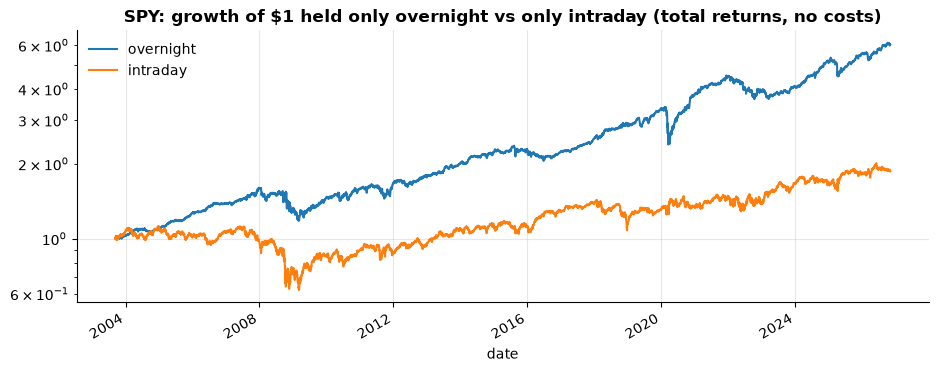

days,overnight / yr,intraday / yr
u32,f64,f64
5824,0.083726,0.037344


In [9]:
spy = p.summaries("SPY").sort("date").drop_nulls(["ret_overnight", "ret_intraday"])
cum = spy.select("date", overnight=(pl.col("ret_overnight").log1p().cum_sum()).exp(),
                 intraday=(pl.col("ret_intraday").log1p().cum_sum()).exp())
ax = cum.to_pandas().set_index("date").plot(logy=True, figsize=(11, 4))
ax.set_title("SPY: growth of $1 held only overnight vs only intraday (total returns, no costs)")
plt.show()
spy.select(pl.len().alias("days"), (pl.col("ret_overnight").mean() * 252).alias("overnight / yr"),
           (pl.col("ret_intraday").mean() * 252).alias("intraday / yr"))

In [10]:
m = spy.drop_nulls(["ret_first30", "ret_last30"]).with_columns(
    period=(pl.col("date").dt.year() // 5 * 5),
    from_close=(1 + pl.col("ret_overnight")) * (1 + pl.col("ret_first30")) - 1)   # the paper's predictor

def slope(df, x):
    a, y = df[x].to_numpy(), df["ret_last30"].to_numpy()
    r = np.corrcoef(a, y)[0, 1]
    return {"slope": round(np.polyfit(a, y, 1)[0], 4), "t": round(r * np.sqrt((len(a) - 2) / (1 - r * r)), 1)}

rows = [("all", m)] + [(f"{k}-{k + 4}", g) for (k,), g in sorted(m.group_by("period"))]
pl.DataFrame([{"period": name, "days": g.height,
               **{f"prev close->10:00 {k}": v for k, v in slope(g, "from_close").items()},
               **{f"open->10:00 {k}": v for k, v in slope(g, "ret_first30").items()}} for name, g in rows])

period,days,prev close->10:00 slope,prev close->10:00 t,open->10:00 slope,open->10:00 t
str,i64,f64,f64,f64,f64
"""all""",5824,0.0522,8.0,-0.0646,-4.4
"""2000-2004""",330,0.001,0.0,0.0234,0.4
"""2005-2009""",1259,0.1287,6.8,-0.1577,-4.3
"""2010-2014""",1258,0.0536,4.6,0.0424,1.5
"""2015-2019""",1258,-0.0041,-0.4,0.022,0.9
"""2020-2024""",1258,0.0269,2.2,-0.0825,-2.6
"""2025-2029""",461,-0.0076,-0.5,0.0599,1.7


Measured as in the paper, from the previous close, the first half hour predicts the last one
over the whole sample (t about 8), strongly in 2005-2014, not in 2015-2019, weakly in 2020-2024 (t 2.2) and not since 2025. Measured
from the open, so without the overnight move, the sign flips: what predicts is mostly the
overnight gap. The last half hour here runs from 15:30 to the official close, auction
included, so trading it needs a market-on-close order. Whether anything is left after spreads
and the auction is the first question for `tactical-cube`.